## Atividade em aula

1. Apresente um resumo estatístico das variáveis da base (média, mediana, desvio padrão, valores mínimos, máximos e quartis).&nbsp;Verifique a existência de valores ausentes ou discrepantes&nbsp;e descreva brevemente a distribuição dos dados.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# Carregando o dataset a partir do arquivo local disponível no ambiente ou usando o link RAW correto
df = pd.read_csv('https://raw.githubusercontent.com/ronan-cunha/machine-learning-course/259e8733eaab7c7dadbd09152c833dadc9b07668/Data/Country-data.csv')
display(df.head())
df.info()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB


In [10]:
# Resumo estatístico para variáveis numéricas
resumo = df.describe().T
# Adicionando a mediana
resumo['median'] = df.median(numeric_only=True)
resumo['null'] = df.isnull().sum()
resumo = resumo[['mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max', 'null']]

print("--- Resumo Estatístico das Variáveis ---")
display(resumo)

--- Resumo Estatístico das Variáveis ---


,mean,median,std,min,25%,50%,75%,max,null
child_mort,38.270060,19.30,40.328931,2.6000,8.250,19.30,62.10,208.00,0
exports,41.108976,35.00,27.412010,0.1090,23.800,35.00,51.35,200.00,0
health,6.815689,6.32,2.746837,1.8100,4.920,6.32,8.60,17.90,0
imports,46.890215,43.30,24.209589,0.0659,30.200,43.30,58.75,174.00,0
income,17144.688623,9960.00,19278.067698,609.0000,3355.000,9960.00,22800.00,125000.00,0
inflation,7.781832,5.39,10.570704,-4.2100,1.810,5.39,10.75,104.00,0
life_expec,70.555689,73.10,8.893172,32.1000,65.300,73.10,76.80,82.80,0
total_fer,2.947964,2.41,1.513848,1.1500,1.795,2.41,3.88,7.49,0
gdpp,12964.155689,4660.00,18328.704809,231.0000,1330.000,4660.00,14050.00,105000.00,0


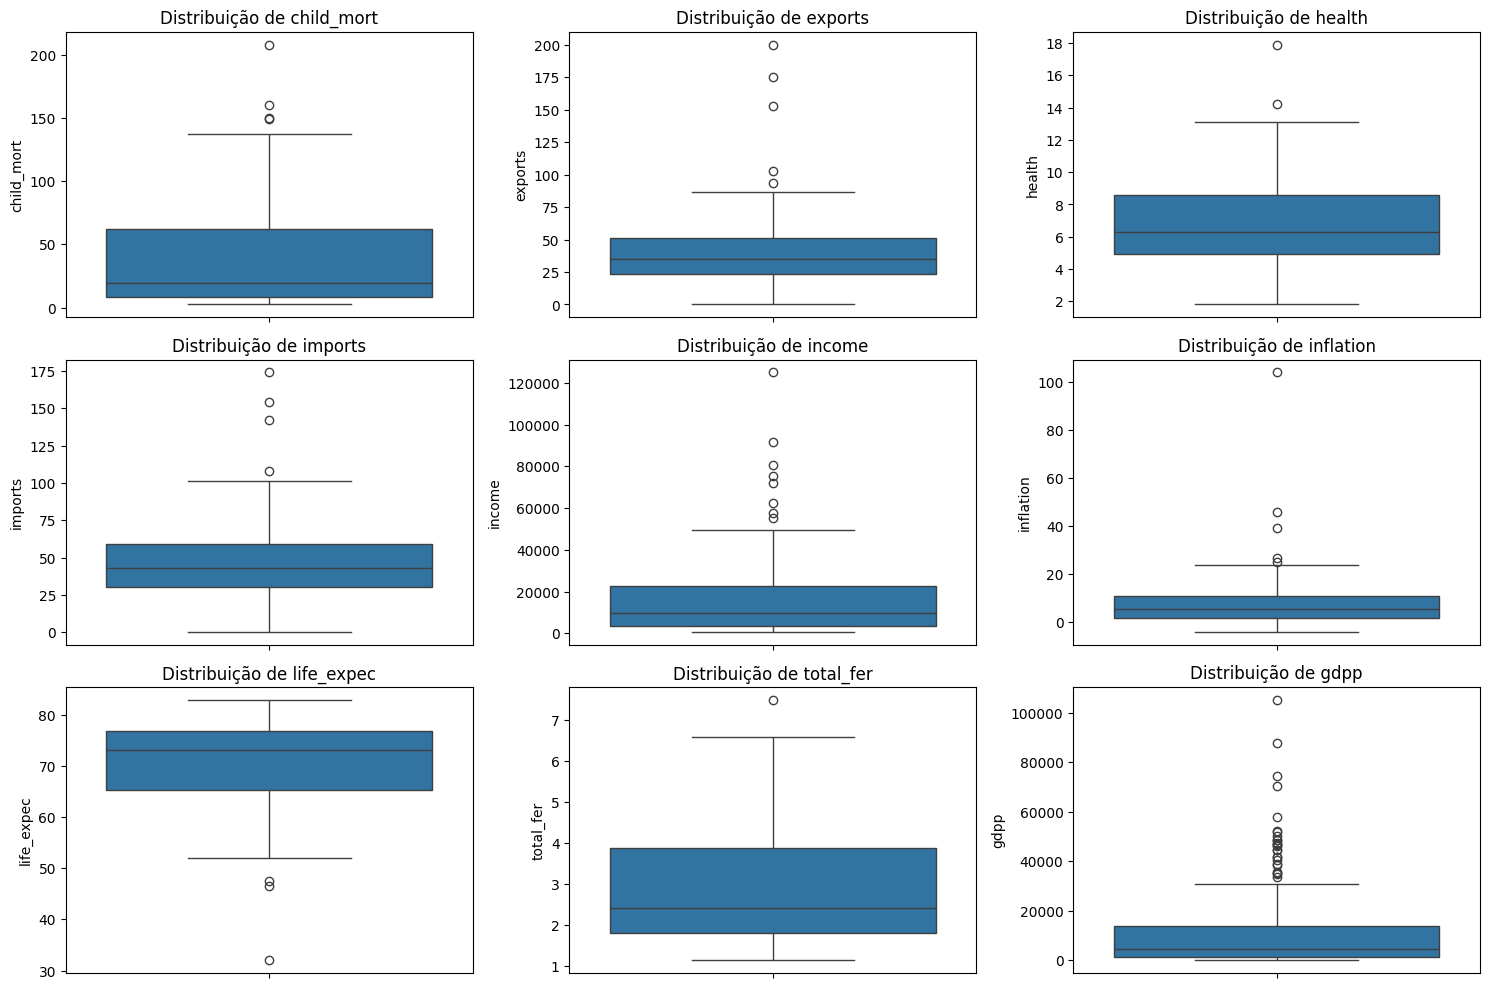

In [11]:
num_cols = df.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Distribuição de {col}')
plt.tight_layout()
plt.show()

2. Aplique o algoritmo K-Means para segmentar os países em grupos homogêneos. Justifique a escolha do número de clusters utilizado através do Método do Cotovelo ou Análise de Silhueta. Descreva o perfil socioeconômico de cada grupo formado com base nas médias das variáveis.

In [17]:
# Padronização das
X = df.drop(columns=['country'])

scaler = StandardScaler()
x_scaled = scaler.fit_transform(X)

x_scaled_df = pd.DataFrame(x_scaled, columns=X.columns)
display(x_scaled_df.head())

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.291532,-1.138280,0.279088,-0.082455,-0.808245,0.157336,-1.619092,1.902882,-0.679180
1,-0.538949,-0.479658,-0.097016,0.070837,-0.375369,-0.312347,0.647866,-0.859973,-0.485623
2,-0.272833,-0.099122,-0.966073,-0.641762,-0.220844,0.789274,0.670423,-0.038404,-0.465376
3,2.007808,0.775381,-1.448071,-0.165315,-0.585043,1.387054,-1.179234,2.128151,-0.516268
4,-0.695634,0.160668,-0.286894,0.497568,0.101732,-0.601749,0.704258,-0.541946,-0.041817


### Passo 3: Algoritmo K-Means
Vamos aplicar o K-Means e justificar a escolha do número ideal de clusters ($K$) utilizando o Método do Cotovelo (Elbow Method) e a Análise de Silhueta.

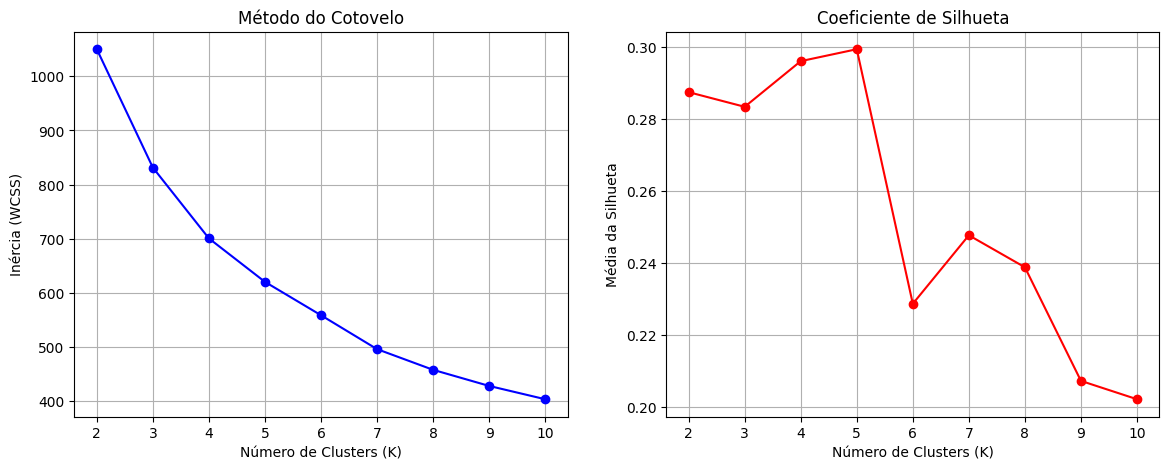

In [20]:
inertia = []
silhouette_coefficients = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k,  init='k-means++', random_state=42, n_init=10)
    kmeans.fit(x_scaled)
    inertia.append(kmeans.inertia_)
    score = silhouette_score(x_scaled, kmeans.labels_)
    silhouette_coefficients.append(score)

# Plotando as métricas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Cotovelo
ax1.plot(K_range, inertia, marker='o', color='b')
ax1.set_title('Método do Cotovelo')
ax1.set_xlabel('Número de Clusters (K)')
ax1.set_ylabel('Inércia (WCSS)')
ax1.grid(True)

# Silhueta
ax2.plot(K_range, silhouette_coefficients, marker='o', color='r')
ax2.set_title('Coeficiente de Silhueta')
ax2.set_xlabel('Número de Clusters (K)')
ax2.set_ylabel('Média da Silhueta')
ax2.grid(True)

plt.show()

In [25]:
# Descrição dos clusters
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init=10)
df['kmeans_cluster'] = kmeans_final.fit_predict(x_scaled)

# Contagem de países em cada cluster
print("--- Contagem de países por cluster ---")
print(df['kmeans_cluster'].value_counts())

# Calculando a média das variáveis originais para cada grupo
perfis_kmeans = df.groupby('kmeans_cluster')[num_cols].mean()
print("--- Perfil Médio de cada Cluster (K-Means) ---")
display(perfis_kmeans)



--- Contagem de países por cluster ---
kmeans_cluster
0    84
1    47
3    32
2     3
4     1
Name: count, dtype: int64
--- Perfil Médio de cada Cluster (K-Means) ---


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
kmeans_cluster,,,,,,,,,
0,21.614286,40.976060,6.169048,47.518642,12801.071429,7.618857,73.004762,2.277619,6581.809524
1,90.793617,29.661915,6.462553,43.680851,3870.702128,9.951809,59.212766,4.974043,1900.255319
2,4.133333,176.000000,6.793333,156.666667,64033.333333,2.468000,81.433333,1.380000,57566.666667
3,5.181250,46.118750,9.088437,40.584375,44021.875000,2.513844,80.081250,1.788437,42118.750000
4,130.000000,25.300000,5.070000,17.400000,5150.000000,104.000000,60.500000,5.840000,2330.000000


3. Aplique o algoritmo DBSCAN para agrupar os países com base na densidade dos dados. Justifique a escolha dos hiperparâmetros. Descreva as características dos grupos formados e identifique quais países foram classificados como ruído/outliers.

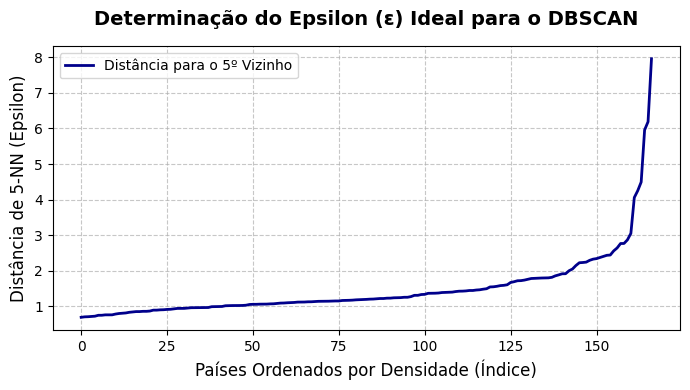

In [71]:
from sklearn.neighbors import NearestNeighbors

# Ajustando o método dos vizinhos mais próximos para encontrar o epsilon ótimo do DBSCAN
num_viz = 5
neighbors = NearestNeighbors(n_neighbors=num_viz)
neighbors_fit = neighbors.fit(x_scaled)
distances, indices = neighbors_fit.kneighbors(x_scaled)

# Selecionando e ordenando a distância do 5º vizinho
distances = np.sort(distances[:, num_viz-1])

# Construindo a figura com labels aprimorados
plt.figure(figsize=(7, 4))
plt.plot(distances, color='darkblue', linewidth=2, label='Distância para o 5º Vizinho')

plt.title('Determinação do Epsilon (ε) Ideal para o DBSCAN', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Países Ordenados por Densidade (Índice)', fontsize=12)
plt.ylabel(f'Distância de {num_viz}-NN (Epsilon)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [72]:
# Rodando o DBSCAN baseado na curva acima (por exemplo, eps=2.0, min_samples=5)
dbscan = DBSCAN(eps=2, min_samples=5)
df['dbscan_cluster'] = dbscan.fit_predict(x_scaled)

print("Frequência dos clusters no DBSCAN:")
print(df['dbscan_cluster'].value_counts())

# Exibindo os países classificados como ruídos (outliers)
outliers = df[df['dbscan_cluster'] == -1]
print(f"\nQuantidade de Outliers detectados: {len(outliers)}")
display(outliers[['country', 'gdpp', 'income', 'child_mort']].head(10))

Frequência dos clusters no DBSCAN:
dbscan_cluster
 0    152
-1     15
Name: count, dtype: int64

Quantidade de Outliers detectados: 15


,country,gdpp,income,child_mort
23,Brunei,35300,80600,10.5
49,Equatorial Guinea,17100,33700,111.0
66,Haiti,662,1500,208.0
82,Kuwait,38500,75200,10.8
87,Lesotho,1170,2380,99.7
88,Liberia,327,700,89.3
91,Luxembourg,105000,91700,2.8
98,Malta,21100,28300,6.8
101,"Micronesia, Fed. Sts.",2860,3340,40.0
103,Mongolia,2650,7710,26.1


5. Compare os resultados obtidos pelo K-Means e pelo DBSCAN e indique qual metodologia é a mais adequada para este conjunto de dados.&nbsp;Fundamente sua resposta considerando dois aspectos:

    a) Natureza do problema: a estrutura, o formato e a presença de outliers na base de países;

    b) Métricas de validação interna: compare o desempenho numérico dos algoritmos utilizando indicadores como o coeficiente de Silhueta.

In [73]:
# Coeficiente de Silhueta para K-Means
sil_kmeans = silhouette_score(x_scaled, df['kmeans_cluster'])

# Coeficiente de Silhueta para DBSCAN (excluindo os ruídos)
valid_mask = df['dbscan_cluster'] != -1
valid_labels = df.loc[valid_mask, 'dbscan_cluster']

# A silhueta só pode ser calculada se houver pelo menos 2 clusters distintos formados
if len(valid_labels.unique()) > 1:
    sil_dbscan = silhouette_score(x_scaled[valid_mask], valid_labels)
else:
    sil_dbscan = float('nan')  # Não aplicável por possuir apenas 1 cluster válido

print(f"Coeficiente de Silhueta K-Means: {sil_kmeans:.4f}")
if not np.isnan(sil_dbscan):
    print(f"Coeficiente de Silhueta DBSCAN (apenas clusters válidos): {sil_dbscan:.4f}")
else:
    print("Coeficiente de Silhueta DBSCAN (apenas clusters válidos): Não aplicável (apenas 1 cluster válido formado)")

Coeficiente de Silhueta K-Means: 0.2993
Coeficiente de Silhueta DBSCAN (apenas clusters válidos): Não aplicável (apenas 1 cluster válido formado)
